Mounted at /content/drive
=== METODE 2: SVM EUCLIDEAN DISTANCE (RBF KERNEL) ===
Accuracy  : 0.8385
Precision : 0.7342
Recall    : 0.8385
F1-Score  : 0.7736

Classification Report:
              precision    recall  f1-score   support

   Non-Hoaks       0.12      0.01      0.01       129
       Hoaks       0.85      0.99      0.91       707

    accuracy                           0.84       836
   macro avg       0.49      0.50      0.46       836
weighted avg       0.73      0.84      0.77       836



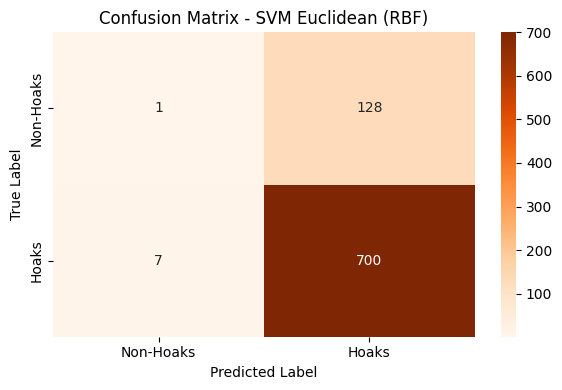

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

from google.colab import drive
drive.mount('/content/drive')
# 1. Load Dataset
df = pd.read_csv('/content/drive/MyDrive/pembelajaran mesin/komdigi_hoaks.csv')

# 2. Preprocessing & Labeling
df['target'] = (df['topics'] == 'Hoaks').astype(int)
text_data = df['title'].fillna('') + " " + df['body_text'].fillna('')
y = df['target']

# 3. Ekstraksi Fitur TF-IDF
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english')
X = vectorizer.fit_transform(text_data)

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Pelatihan Model SVM Euclidean (Kernel RBF berbasis Jarak Euclidean)
print("=== METODE 2: SVM EUCLIDEAN DISTANCE (RBF KERNEL) ===")
model_euclidean = SVC(kernel='rbf', random_state=42)
model_euclidean.fit(X_train, y_train)

# 5. Evaluasi Model
y_pred = model_euclidean.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Non-Hoaks', 'Hoaks']))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=['Non-Hoaks', 'Hoaks'], yticklabels=['Non-Hoaks', 'Hoaks'])
plt.title('Confusion Matrix - SVM Euclidean (RBF)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()